In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics

import os
print('Videos in Colab:', os.path.exists('/content/mob_videos/video_split_fullhd'))
print('Model in Drive:', os.path.exists('/content/drive/MyDrive/model1.pt'))
!ls /content/drive/MyDrive/demo_videos 2>/dev/null

Mounted at /content/drive
Videos in Colab: False
Model in Drive: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from huggingface_hub import snapshot_download
snapshot_download(repo_id="dronefreak/SeaDronesSee",
                  repo_type="dataset", local_dir="/content/sds")

!cd /content && zip -qr sds.zip sds && cp sds.zip /content/drive/MyDrive/
print("Done. Saved to Drive.")

Mounted at /content/drive


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 20964 files:   0%|          | 0/20964 [00:00<?, ?it/s]

HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/SeaDronesSee/resolve/2693d615c7070506be12e6698629fc51d286f18a/data/labels/train/shard_001/289.txt
Rate limited. Waiting 227.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/SeaDronesSee/resolve/2693d615c7070506be12e6698629fc51d286f18a/data/labels/train/shard_001/2892.txt
Rate limited. Waiting 227.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/SeaDronesSee/resolve/2693d615c7070506be12e6698629fc51d286f18a/data/labels/train/shard_001/2893.txt
Rate limited. Waiting 227.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/SeaDronesSee/resolve/2693d615c7070506be12e6698629fc51d286f18a/data/labels/train/shard_001/2895.txt
Rate limited. Waiting 227.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requestin

Done. Saved to Drive.


In [ ]:
import glob, yaml, collections

yml = glob.glob('/content/sds/**/data.yaml', recursive=True)[0]
names = yaml.safe_load(open(yml))['names']
names = names if isinstance(names, list) else [names[k] for k in sorted(names)]

for split in ['train', 'valid', 'val']:
    files = [f for f in glob.glob('/content/sds/**/labels/**/*.txt', recursive=True)
             if f'/{split}/' in f]
    if not files:
        continue
    boxes, imgs = collections.Counter(), collections.Counter()
    for f in files:
        cls = [int(l.split()[0]) for l in open(f) if l.strip()]
        boxes.update(cls)
        imgs.update(set(cls))
    print(split, '| label files:', len(files))
    for k in sorted(boxes):
        print(f'  {names[k]}: {boxes[k]} boxes in {imgs[k]} images')

train | label files: 8930
  swimmer: 37096 boxes in 6898 images
  boat: 13022 boxes in 5870 images
  jetski: 2330 boxes in 2328 images
  life_saving_appliances: 923 boxes in 665 images
  buoy: 4389 boxes in 3722 images
val | label files: 1547
  swimmer: 6206 boxes in 1286 images
  boat: 2214 boxes in 915 images
  jetski: 320 boxes in 320 images
  life_saving_appliances: 330 boxes in 191 images
  buoy: 560 boxes in 352 images


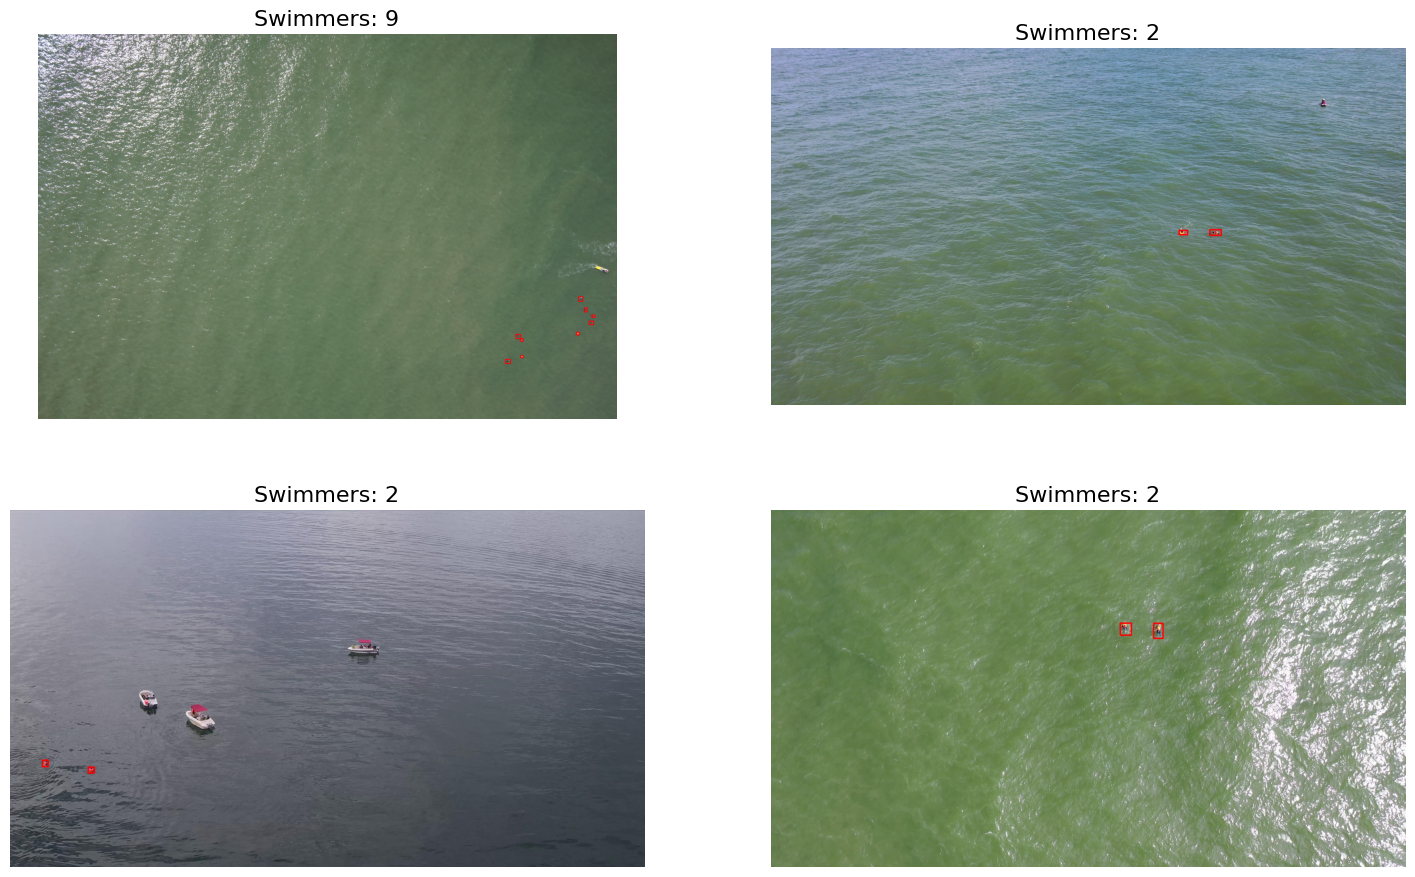

In [ ]:
import glob, random, yaml, cv2, os
import matplotlib.pyplot as plt

yml = glob.glob('/content/sds/**/data.yaml', recursive=True)[0]
names = yaml.safe_load(open(yml))['names']
names = names if isinstance(names, list) else [names[k] for k in sorted(names)]
SWIMMER = names.index('swimmer')

imgs = [p for p in glob.glob('/content/sds/**/train/**/*.*', recursive=True)
        if p.lower().endswith(('.jpg', '.png')) and '/images/' in p]

def swimmers_in(p):
    lbl = p.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    if not os.path.exists(lbl):
        return []
    return [list(map(float, l.split()[1:5])) for l in open(lbl)
            if l.strip() and int(l.split()[0]) == SWIMMER]

with_swimmers = [p for p in random.sample(imgs, 300) if swimmers_in(p)]

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, p in zip(axes.flat, random.sample(with_swimmers, 4)):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    boxes = swimmers_in(p)
    for x, y, bw, bh in boxes:
        x1, y1 = int((x - bw/2) * w), int((y - bh/2) * h)
        x2, y2 = int((x + bw/2) * w), int((y + bh/2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 8)
    ax.imshow(img)
    ax.set_title(f'Swimmers: {len(boxes)}', fontsize=16)
    ax.axis('off')
plt.show()

In [ ]:
import os, glob, random, shutil

random.seed(0)

# 1. Paths
SRC = '/content/sds/data'
DST = '/content/sds_swimmer'
SWIMMER_ID = 0   # swimmer is class 0 in the original data

# 2. Get all image paths
train_images = glob.glob(f'{SRC}/images/train/**/*.jpg', recursive=True)
val_images   = glob.glob(f'{SRC}/images/val*/**/*.jpg', recursive=True)

random.shuffle(train_images)
random.shuffle(val_images)

print('Original train images:', len(train_images))
print('Original val images:', len(val_images))

# 3. Function: copy image + keep only swimmer labels
def copy_split(images, split_name):
    os.makedirs(f'{DST}/{split_name}/images', exist_ok=True)
    os.makedirs(f'{DST}/{split_name}/labels', exist_ok=True)

    swimmer_count = 0
    for img_path in images:
        # copy image
        shutil.copy(img_path, f'{DST}/{split_name}/images/')

        # find its label file
        label_path = img_path.replace('/images/', '/labels/').replace('.jpg', '.txt')
        new_label = f'{DST}/{split_name}/labels/' + os.path.basename(label_path)

        # keep only swimmer lines
        swimmer_lines = []
        if os.path.exists(label_path):
            for line in open(label_path):
                parts = line.split()
                if len(parts) > 0 and int(parts[0]) == SWIMMER_ID:
                    swimmer_lines.append(line.strip())

        swimmer_count += len(swimmer_lines)
        with open(new_label, 'w') as f:
            f.write('\n'.join(swimmer_lines))

    print(f'{split_name}: {len(images)} images, {swimmer_count} swimmers')

# 4. Create the 3 splits
copy_split(train_images[:5000], 'train')
copy_split(train_images[5000:6000], 'test')
copy_split(val_images[:1000], 'val')

# 5. Create data.yaml for YOLO
with open(f'{DST}/data.yaml', 'w') as f:
    f.write(f"path: {DST}\n")
    f.write("train: train/images\n")
    f.write("val: val/images\n")
    f.write("test: test/images\n")
    f.write("names: ['swimmer']\n")

print('data.yaml created')

Original train images: 8930
Original val images: 1547
train: 5000 images, 20992 swimmers
test: 1000 images, 4193 swimmers
val: 1000 images, 4068 swimmers
data.yaml created


In [ ]:
!cd /content && zip -qr sds_swimmer.zip sds_swimmer && cp sds_swimmer.zip /content/drive/MyDrive/
print('Saved to Drive')

Saved to Drive


Train images: 5000
path: /content/sds_swimmer
train: train/images
val: val/images
test: test/images
names: ['swimmer']



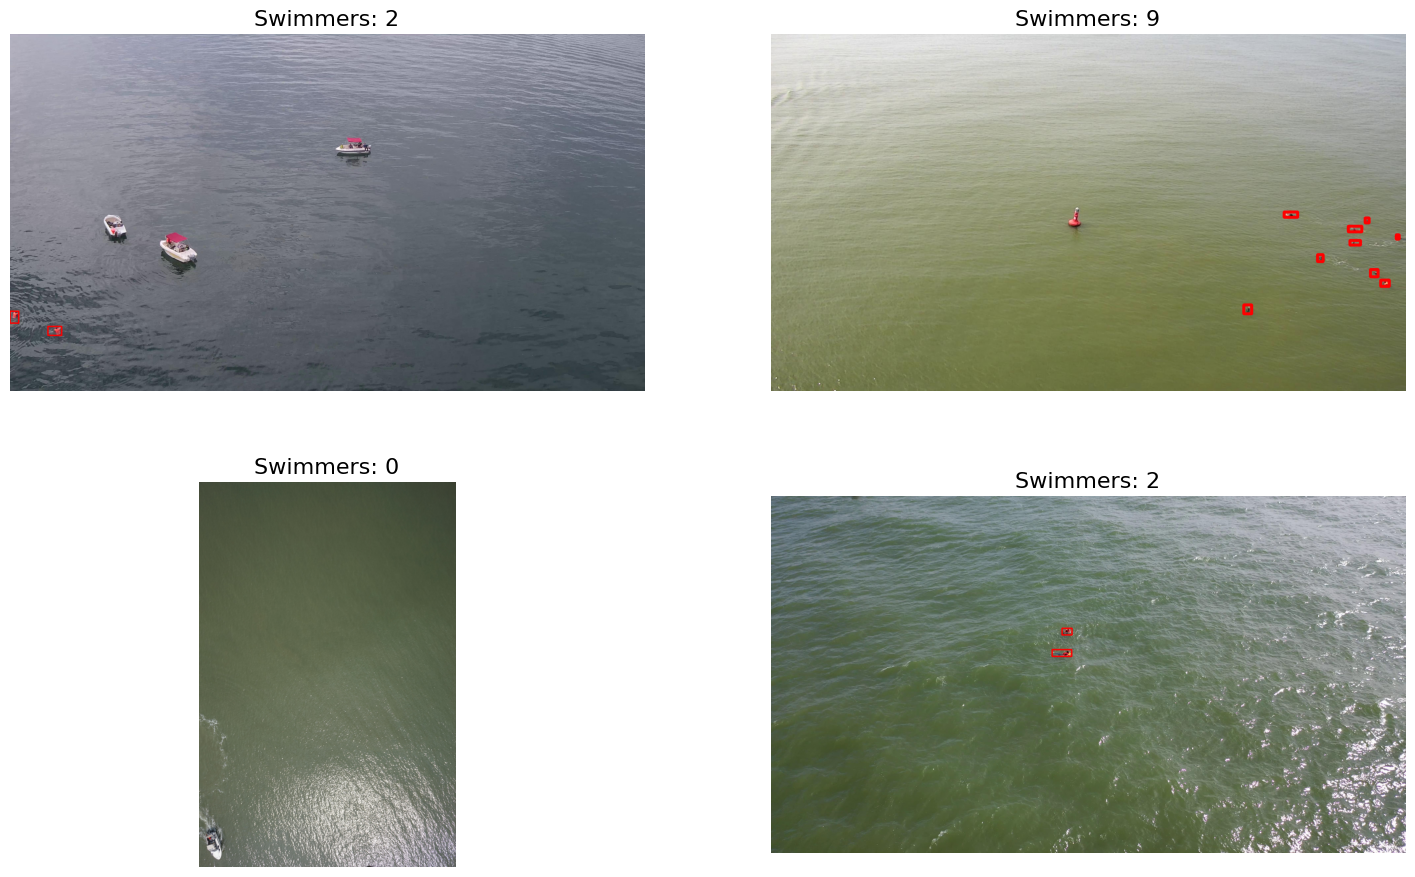

In [ ]:
import glob, random, cv2, os
import matplotlib.pyplot as plt

imgs = glob.glob('/content/sds_swimmer/train/images/*.jpg')
print('Train images:', len(imgs))
print(open('/content/sds_swimmer/data.yaml').read())

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, p in zip(axes.flat, random.sample(imgs, 4)):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl = p.replace('/images/', '/labels/').replace('.jpg', '.txt')
    lines = [l.split() for l in open(lbl) if l.strip()]
    for c, x, y, bw, bh in lines:
        x, y, bw, bh = float(x), float(y), float(bw), float(bh)
        cv2.rectangle(img, (int((x-bw/2)*w), int((y-bh/2)*h)),
                      (int((x+bw/2)*w), int((y+bh/2)*h)), (255, 0, 0), 8)
    ax.imshow(img)
    ax.set_title(f'Swimmers: {len(lines)}', fontsize=16)
    ax.axis('off')
plt.show()